# Get threshold

Launch this notebook with the `deepface` kernel. Use a few pair of images to determine a good threshold separating same people & different people

In [1]:
import sys
import pandas as pd 
import numpy as np
from chefboost import Chefboost as chef
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
sys.path.insert(0,'../')
from helper import build_pairs

## Load face images for threshold computation

In [2]:
m = 512 
samples = 2000
dataset = 'celeba'
model = 'facenet'
mode = 'train'    # 'train' -> train + test_seen splits, 'test' -> test + test2 splits
seed = 0

In [3]:
# Genuine (same-person) and impostor (different-person) embedding-path pairs,
# subsampled to `samples` total, via the shared build_pairs helper.
same_pairs, diff_pairs = build_pairs(dataset, model, mode=mode, samples=samples, seed=seed)

subset_positives = pd.DataFrame(same_pairs, columns=["file_x", "file_y"])
subset_positives["decision"] = "Yes"

subset_negatives = pd.DataFrame(diff_pairs, columns=["file_x", "file_y"])
subset_negatives["decision"] = "No"

df = pd.concat([subset_positives, subset_negatives]).reset_index(drop=True)
print(f"{len(subset_positives)} genuine + {len(subset_negatives)} impostor pairs "
      f"({dataset}/{model}, mode={mode})")

1000 genuine + 1000 impostor pairs (celeba/facenet, mode=train)


In [4]:
files = df['file_x'].tolist() + df['file_y'].tolist()
files = list(set(files))  # Remove duplicates

# build_pairs returns full embedding paths, so load each directly (L2-normalised).
embeddings = dict()
for file in files:
    emb = np.load(file)
    embeddings[file] = emb / np.linalg.norm(emb)
print(f"loaded {len(embeddings)} unique embeddings")

loaded 2000 unique embeddings


In [5]:
instances = df[["file_x", "file_y"]].values.tolist()
distances = []
for instance in instances:
    emb1 = np.array(embeddings[instance[0]])
    emb2 = np.array(embeddings[instance[1]])
    emb1 = emb1/np.linalg.norm(emb1)
    emb2 = emb2/np.linalg.norm(emb2)
    distance = np.linalg.norm(emb1 - emb2) # l2 distance
    # distance = np.dot(emb1, emb2)
    distances.append(distance)
df["distance"] = distances

In [6]:
print(df[df.decision == 'Yes']['distance'].mean())
tp_mean = round(df[df.decision == "Yes"]['distance'].mean(), 4); print(tp_mean)
tp_std = round(df[df.decision == "Yes"]['distance'].std(), 4); print(tp_std)
fp_mean = round(df[df.decision == "No"]['distance'].mean(), 4); print(fp_mean)
fp_std = round(df[df.decision == "No"]['distance'].std(), 4); print(fp_std)

0.8065287758620616
0.8065
0.2261
1.3988
0.1099


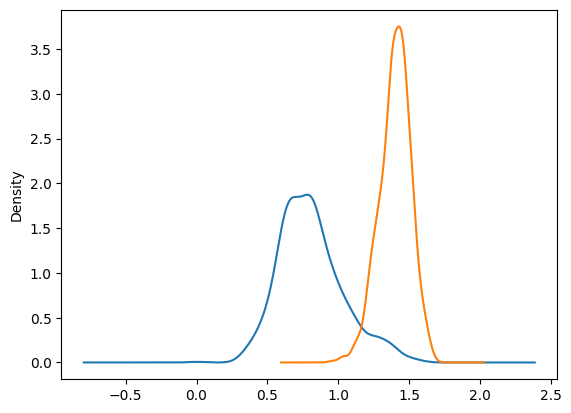

In [7]:
df[df.decision == "Yes"].distance.plot.kde()
df[df.decision == "No"].distance.plot.kde()
plt.show()

### Decision tree threshold using C4.5

In [8]:
config = {'algorithm': 'C4.5'}
tmp_df = df[['distance', 'decision']].rename(columns = {"decision": "Decision"}).copy()
model = chef.fit(tmp_df, config)

26-06-19 03:50:39 - C4.5 tree is going to be built...
26-06-19 03:50:39 - -------------------------
26-06-19 03:50:39 - finished in 0.1494443416595459 seconds
26-06-19 03:50:39 - -------------------------
26-06-19 03:50:39 - Evaluate train set
26-06-19 03:50:39 - -------------------------
26-06-19 03:50:39 - Accuracy: 94.25% on 2000 instances
26-06-19 03:50:39 - Labels: ['Yes' 'No']
26-06-19 03:50:39 - Confusion matrix: [[892, 7], [108, 993]]
26-06-19 03:50:39 - Precision: 99.2214%, Recall: 89.2%, F1: 93.9442%


In [9]:
threshold_dtree = 1.1027 # facenet
df['prediction'] = df.apply(lambda x : 'Yes' if x['distance'] < threshold_dtree else 'No', axis = 1)

In [10]:
cm = confusion_matrix(df.decision.values, df.prediction.values)
print(cm)
tn, fp, fn, tp = cm.ravel()
recall = tp / (tp + fn)
precision = tp / (tp + fp)
accuracy = (tp + tn)/(tn + fp +  fn + tp)
f1 = 2 * (precision * recall) / (precision + recall)


[[993   7]
 [108 892]]


In [11]:
print(tn, fp, fn, tp)
print(f"true negative rate: {tn/(tn + fp)*100}, false positive rate: {fp/(tn + fp)*100}, true positive rate: {tp/(tp + fn)*100}, false negative rate: {fn/(tp + fn)*100}")

993 7 108 892
true negative rate: 99.3, false positive rate: 0.7000000000000001, true positive rate: 89.2, false negative rate: 10.8


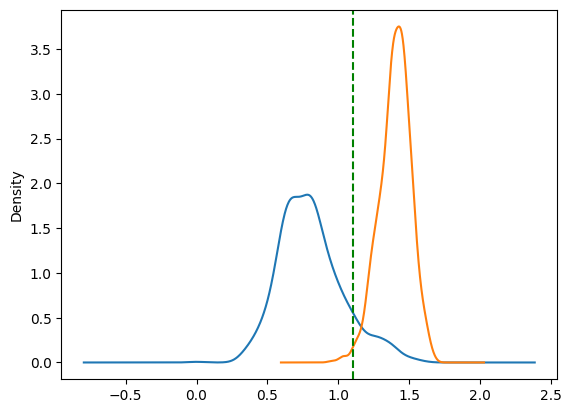

In [12]:
df[df.decision == "Yes"].distance.plot.kde()
df[df.decision == "No"].distance.plot.kde()
plt.axvline(x=threshold_dtree, color='g', linestyle='--', label='Threshold DTree')
plt.show()